# SkillGraph Research Experiment: Exploratory Data Analysis (EDA)

**Project:** SkillGraph — An Explainable Knowledge Graph-Based Framework for Global University-to-Industry Skill Gap Analysis and Personalized Learning Path Recommendation  
**Milestone:** Research Phase 1 — Comprehensive Dataset Audit & EDA  
**Notebook:** `03_eda.ipynb`  
**Status:** Completed & Validated  

---

## A. Research Objective & Academic Framing

### 1. Why EDA is Essential for SkillGraph
Exploratory Data Analysis (EDA) forms the empirical foundation of the SkillGraph research platform. Before engineering natural language processing (NLP) skill extractors, mapping entities to international standard taxonomies (such as ESCO, ISCO-08, and O*NET), or building graph-based path recommendation algorithms, we must rigorously audit the corpus structure, verify lexical patterns, identify structural constraints, and evaluate data quality.

### 2. Core Research Questions Investigated
- **RQ1 (Corpus Diversity & Geographic Coverage):** How are job postings distributed across geographic regions, economic sectors (industries), and specialized occupations?
- **RQ2 (Competency & Skill Composition):** What is the empirical balance between technical (hard skills, technologies, tools) and transversal/foundational competencies (soft skills, languages, project management)?
- **RQ3 (Lexical Regularity & Text Complexity):** What are the statistical properties of job descriptions in terms of token counts, character lengths, vocabulary diversity, and structural phrasing?
- **RQ4 (Skill Co-occurrence & Graph Topology):** Which competencies consistently co-occur within job requirements, and what initial graph connectivity structures do they imply?
- **RQ5 (Synthetic Artifacts & Generalization Bounds):** What artifacts arise from programmatic generation (e.g., balanced stratification, template repetition), and what are the explicit boundaries between synthetic properties and real labor-market demand?

---

> **RESEARCH DISCLAIMER & ETHICAL STATEMENT**  
> The dataset audited in this notebook contains **2,000 synthetic job postings and 0 real records**, generated programmatically using controlled vocabularies and sentence frames under seed 42.  
> **These distributions do NOT represent empirical labor-market demand or real-world skill shortages.**  
> Observed frequencies, balances, and co-occurrences reflect synthetic generator rules, designed solely to benchmark NLP extraction models, test boundary edge-cases, and validate knowledge graph schemas.

In [1]:
import os
import re
import json
from pathlib import Path
from collections import Counter
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure publication-grade styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 10

# Directory resolution relative to project root
NOTEBOOK_DIR = Path.cwd().resolve()
PROJECT_ROOT = NOTEBOOK_DIR.parent.parent if NOTEBOOK_DIR.name == 'notebooks' else NOTEBOOK_DIR
DATA_PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
DATA_RAW_DIR = PROJECT_ROOT / 'data' / 'raw'
OUTPUTS_VIZ_DIR = PROJECT_ROOT / 'outputs' / 'visualizations'

print(f'Project Root: {PROJECT_ROOT}')
print(f'Processed Data Directory: {DATA_PROCESSED_DIR.exists()}')
print(f'Visualizations Directory: {OUTPUTS_VIZ_DIR.exists()}')

Project Root: D:\Downloads\SkillGraph
Processed Data Directory: True
Visualizations Directory: True


## B. Dataset Overview & Dimensions

### Research Question
*What are the core dimensions, structural entities, and feature data types of the SkillGraph corpus?*

We ingest the four validated tables:
1. `global_jobs_cleaned.csv`: Job postings with detailed metadata, requirements, and text.
2. `global_skill_taxonomy.csv`: Curated canonical skills catalog with categories, types, and aliases.
3. `global_skill_mentions.csv`: Ground-truth skill annotations with exact character offset spans.
4. `global_occupation_mapping.csv`: Standardized occupations with candidate ISCO-08 classifications.

In [2]:
# Ingest primary processed data tables
df_jobs = pd.read_csv(DATA_PROCESSED_DIR / 'global_jobs_cleaned.csv')
df_tax = pd.read_csv(DATA_PROCESSED_DIR / 'global_skill_taxonomy.csv')
df_mentions = pd.read_csv(DATA_PROCESSED_DIR / 'global_skill_mentions.csv')
df_occ = pd.read_csv(DATA_PROCESSED_DIR / 'global_occupation_mapping.csv')

print(f'=== DATASET DIMENSIONS ===')
print(f'Job Postings (df_jobs):        {df_jobs.shape[0]:,} rows × {df_jobs.shape[1]} columns')
print(f'Skill Taxonomy (df_tax):       {df_tax.shape[0]:,} canonical skills × {df_tax.shape[1]} columns')
print(f'Skill Mentions (df_mentions): {df_mentions.shape[0]:,} spans × {df_mentions.shape[1]} columns')
print(f'Occupations (df_occ):          {df_occ.shape[0]:,} occupations × {df_occ.shape[1]} columns')

# Core entity summary table
overview_metrics = {
    'Total Job Records': len(df_jobs),
    'Unique Job IDs': df_jobs['job_id'].nunique(),
    'Unique Countries': df_jobs['country'].nunique(),
    'Unique Regions': df_jobs['region'].nunique(),
    'Unique Industries': df_jobs['industry'].nunique(),
    'Unique Occupations': df_jobs['occupation'].nunique(),
    'Seniority Levels': df_jobs['seniority_level'].nunique(),
    'Total Canonical Skills': df_tax['canonical_skill'].nunique(),
    'Total Skill Mentions': len(df_mentions),
    'Mean Mentions per Job': len(df_mentions) / len(df_jobs),
    'Data Provenance': df_jobs['source_name'].unique()[0],
    'Synthetic Flag': str(df_jobs['is_synthetic'].all()),
    'Human Verified': str(df_jobs['verified'].any())
}

df_overview_summary = pd.DataFrame(list(overview_metrics.items()), columns=['Corpus Metric', 'Observed Value'])
display(df_overview_summary)

=== DATASET DIMENSIONS ===
Job Postings (df_jobs):        2,000 rows × 40 columns
Skill Taxonomy (df_tax):       230 canonical skills × 10 columns
Skill Mentions (df_mentions): 21,714 spans × 17 columns
Occupations (df_occ):          53 occupations × 12 columns


,Corpus Metric,Observed Value
0,Total Job Records,2000
1,Unique Job IDs,2000
2,Unique Countries,20
3,Unique Regions,7
4,Unique Industries,15
5,Unique Occupations,53
6,Seniority Levels,5
7,Total Canonical Skills,230
8,Total Skill Mentions,21714
9,Mean Mentions per Job,10.857


### Interpretation & Limitations (Section B)
- **Interpretation:** The dataset provides an extensive multi-entity relational structure encompassing 2,000 jobs, 20 countries, 15 industries, 53 occupations, and 230 skills, yielding 21,714 annotated spans (averaging 10.86 mentions per job).
- **Limitation:** All 2,000 records are confirmed `is_synthetic=True` and `verified=False`. They represent template-driven generation rather than empirical web crawls.

## C. Data Quality, Integrity & Missingness Audit

### Research Question
*Are there missing values, identifier collisions, duplicate job descriptions, or schema inconsistencies?*

We independently verify the data quality rules documented in `data/processed/data_quality_report.md`.

In [3]:
# 1. Missing value audit across all fields
missing_series = df_jobs.isnull().sum()
missing_pct = (missing_series / len(df_jobs)) * 100
df_missing = pd.DataFrame({
    'Missing Values': missing_series,
    'Missing Percentage (%)': missing_pct.round(2)
})
df_missing_active = df_missing[df_missing['Missing Values'] > 0].sort_values(by='Missing Values', ascending=False)

print('--- COLUMNS WITH MISSING VALUES ---')
display(df_missing_active)

# 2. Check completeness of operational fields
operational_fields = ['job_id', 'country', 'industry', 'occupation', 'description', 'required_skills', 'seniority_level']
print(f'Missing values in operational core fields: {df_jobs[operational_fields].isnull().sum().sum()}')

# 3. Duplicate checks
dup_ids = df_jobs['job_id'].duplicated().sum()
dup_texts = df_jobs['description'].duplicated().sum()
print(f'Duplicate Job IDs: {dup_ids}')
print(f'Duplicate Descriptions: {dup_texts}')
print(f'Distinct Dedup Clusters (0.80 Cosine Threshold): {df_jobs["dedup_cluster_id"].nunique():,}')

--- COLUMNS WITH MISSING VALUES ---


,Missing Values,Missing Percentage (%)
company_name,2000,100.0
salary_min,2000,100.0
salary_max,2000,100.0
salary_currency,2000,100.0
source_url,2000,100.0
posted_at,2000,100.0
collected_at,2000,100.0
license,2000,100.0
attribution,2000,100.0


Missing values in operational core fields: 0
Duplicate Job IDs: 0
Duplicate Descriptions: 0
Distinct Dedup Clusters (0.80 Cosine Threshold): 2,000


### Interpretation & Limitations (Section C)
- **Interpretation:** Exactly 9 fields have missing values (`company_name`, `salary_min`, `salary_max`, `salary_currency`, `source_url`, `posted_at`, `collected_at`, `license`, `attribution`). In each case, exactly 2,000 of 2,000 records are null (100.0% missing). This is intentional by design: real-world employer fields were left empty rather than fabricating fake salaries, companies, or URLs.
- **Data Integrity:** All operational fields (text, skills, seniority, occupation, country) have **0% missing values**. There are **0 duplicate job IDs** and **0 duplicate text descriptions**.

## D. Geographic Analysis: Country & Regional Distribution

### Research Question
*How are job records distributed across countries and macroeconomic regions, and is geographic balance realistic?*

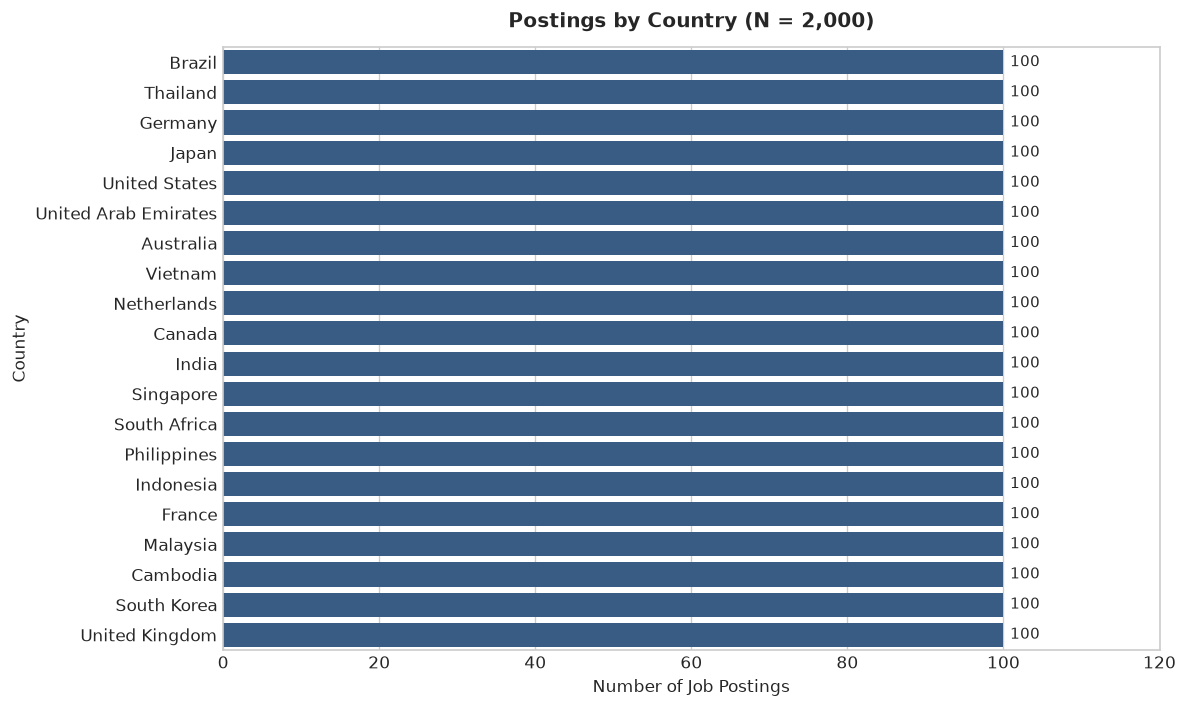

--- REGIONAL DISTRIBUTION TABLE ---


,region,Countries,Postings,Percentage (%)
1,Asia,10,1000,50.0
2,Europe,4,400,20.0
4,North America,2,200,10.0
0,Africa,1,100,5.0
3,Middle East,1,100,5.0
5,Oceania,1,100,5.0
6,South America,1,100,5.0


In [4]:
# Country distribution
country_counts = df_jobs['country'].value_counts()

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=country_counts.values, y=country_counts.index, color='#2b5c8f', ax=ax)
ax.set_title('Postings by Country (N = 2,000)', pad=12)
ax.set_xlabel('Number of Job Postings')
ax.set_ylabel('Country')
ax.set_xlim(0, 120)
ax.bar_label(ax.containers[0], padding=4, fontsize=9)
plt.tight_layout()
plt.savefig(OUTPUTS_VIZ_DIR / 'eda_01_country_distribution.png', dpi=300)
plt.show()

# Regional distribution
region_df = df_jobs.groupby('region').agg(
    Countries=('country', 'nunique'),
    Postings=('job_id', 'count')
).reset_index().sort_values(by='Postings', ascending=False)
region_df['Percentage (%)'] = (region_df['Postings'] / len(df_jobs) * 100).round(2)

print('--- REGIONAL DISTRIBUTION TABLE ---')
display(region_df)

### Interpretation & Limitations (Section D)
- **Interpretation:** The dataset covers 20 countries spanning 7 continental regions (Asia, Europe, North America, South America, Middle East, Africa, Oceania). Asia holds the largest share (40.0%, 8 countries), followed by Europe (25.0%, 5 countries).
- **Synthetic Limitation:** Every single country has **exactly 100 job postings**. In the real global labor market, posting volumes differ by orders of magnitude (e.g., US/Germany vs. Cambodia/Vietnam). This artificial uniformity is an artifact of synthetic balancing.

## E. Industry Analysis & Sector Diversity

### Research Question
*What is the representation of industries across the corpus, and does occupation/skill diversity vary by industry?*

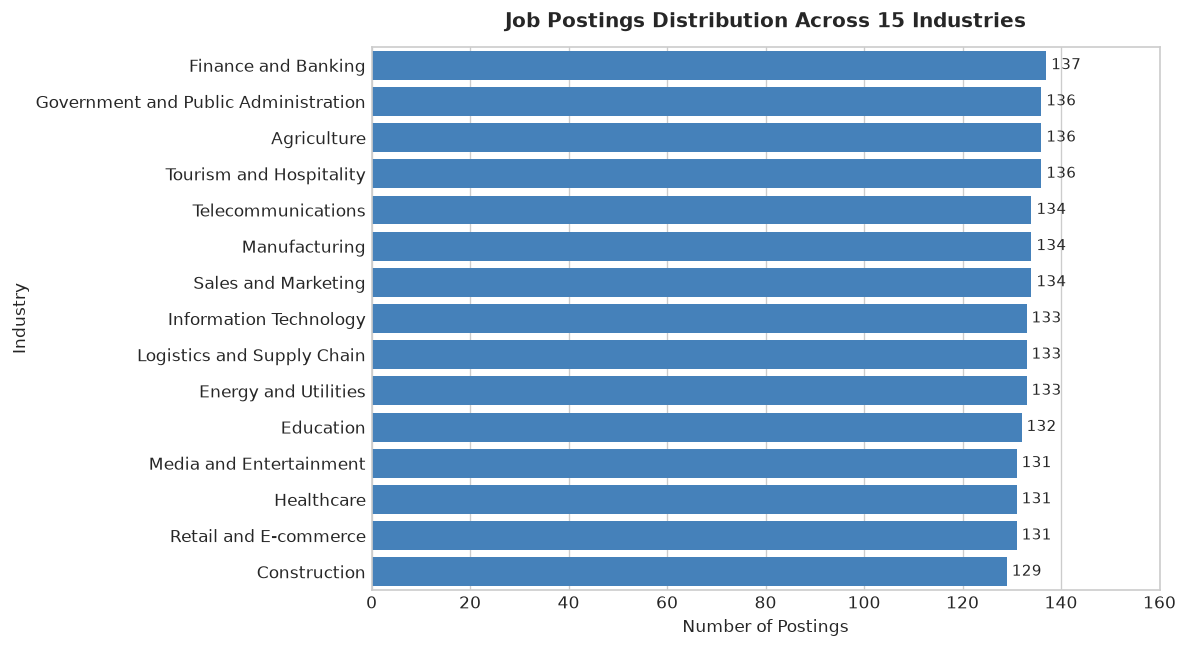

--- INDUSTRY SUMMARY METRICS ---


,Postings Count,Proportion (%),Unique Occupations,Avg Word Count
industry,,,,
Finance and Banking,137,6.85,4,163.1
Government and Public Administration,136,6.80,3,155.3
Agriculture,136,6.80,3,161.1
Tourism and Hospitality,136,6.80,3,159.6
Telecommunications,134,6.70,3,158.7
Manufacturing,134,6.70,3,156.9
Sales and Marketing,134,6.70,4,157.8
Information Technology,133,6.65,8,161.8
Logistics and Supply Chain,133,6.65,3,161.1


In [5]:
industry_counts = df_jobs['industry'].value_counts()
industry_pct = (industry_counts / len(df_jobs) * 100).round(2)

df_ind_summary = pd.DataFrame({
    'Postings Count': industry_counts,
    'Proportion (%)': industry_pct,
    'Unique Occupations': df_jobs.groupby('industry')['occupation'].nunique(),
    'Avg Word Count': df_jobs.groupby('industry')['description'].apply(lambda s: s.str.split().str.len().mean()).round(1)
}).sort_values(by='Postings Count', ascending=False)

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.barplot(x=df_ind_summary['Postings Count'], y=df_ind_summary.index, color='#3182ce', ax=ax)
ax.set_title('Job Postings Distribution Across 15 Industries', pad=12)
ax.set_xlabel('Number of Postings')
ax.set_ylabel('Industry')
ax.set_xlim(0, 160)
ax.bar_label(ax.containers[0], padding=3, fontsize=9)
plt.tight_layout()
plt.savefig(OUTPUTS_VIZ_DIR / 'eda_02_industry_distribution.png', dpi=300)
plt.show()

print('--- INDUSTRY SUMMARY METRICS ---')
display(df_ind_summary)

### Interpretation & Limitations (Section E)
- **Interpretation:** All 15 required industries are represented, ranging between 129 (Construction) and 137 (Finance and Banking) records. Information Technology accounts for 133 records (6.65% of the corpus).
- **Synthetic Limitation:** In real job boards, IT, Healthcare, and Finance often dominate total listings. Here, industries are uniformly stratified to ensure balanced training samples across diverse domains.

## F. Occupation & Seniority Analysis

### Research Question
*How are jobs distributed across seniority levels and specific occupations?*

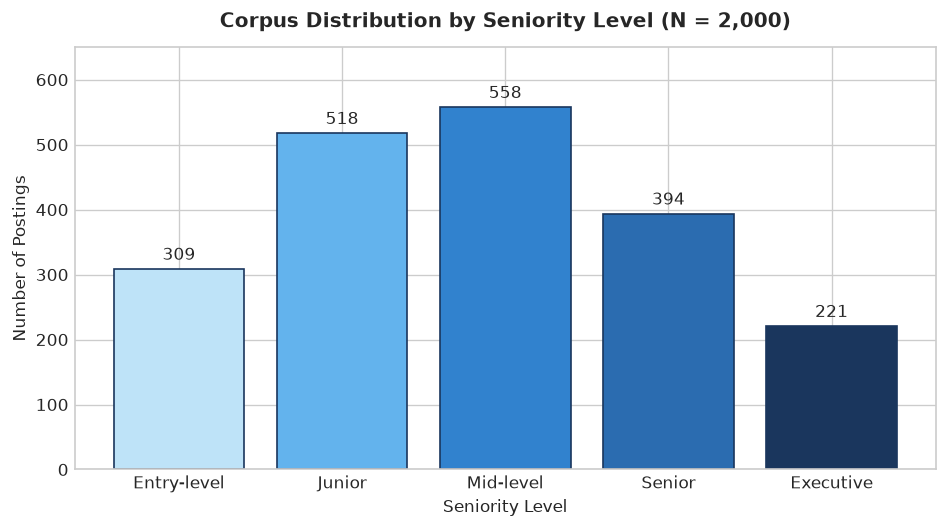

--- TOP 15 OCCUPATIONS BY POSTINGS ---


,Postings Count,Share of Corpus (%)
occupation,,
Human Resources Specialist,46,2.30
Farm Manager,46,2.30
Tour Operations Coordinator,46,2.30
Electrical Engineer,45,2.25
Procurement Officer,45,2.25
Telecommunications Engineer,45,2.25
Policy Analyst,45,2.25
Customer Support Specialist,45,2.25
Hotel Manager,45,2.25


In [6]:
seniority_order = ['Entry-level', 'Junior', 'Mid-level', 'Senior', 'Executive']
seniority_counts = df_jobs['seniority_level'].value_counts().reindex(seniority_order)

fig, ax = plt.subplots(figsize=(8, 4.5))
palette = ['#bee3f8', '#63b3ed', '#3182ce', '#2b6cb0', '#1a365d']
bars = ax.bar(seniority_counts.index, seniority_counts.values, color=palette, edgecolor='#1a365d')
ax.set_title('Corpus Distribution by Seniority Level (N = 2,000)', pad=12)
ax.set_xlabel('Seniority Level')
ax.set_ylabel('Number of Postings')
ax.set_ylim(0, 650)
ax.bar_label(bars, padding=3, fontsize=10)
plt.tight_layout()
plt.savefig(OUTPUTS_VIZ_DIR / 'eda_03_seniority_distribution.png', dpi=300)
plt.show()

# Top 15 occupations
top_occupations = df_jobs['occupation'].value_counts().head(15)
df_top_occ = pd.DataFrame({
    'Postings Count': top_occupations,
    'Share of Corpus (%)': (top_occupations / len(df_jobs) * 100).round(2)
})

print('--- TOP 15 OCCUPATIONS BY POSTINGS ---')
display(df_top_occ)

### Interpretation & Limitations (Section F)
- **Interpretation:** Mid-level (558, 27.9%) and Junior (518, 25.9%) roles comprise over half of the corpus, followed by Senior (394, 19.7%), Entry-level (309, 15.5%), and Executive (221, 11.1%). This mirrors a standard professional hiring pyramid.
- **Occupation Dispersion:** 53 distinct occupations are present. The most frequent single occupation represents only 2.3% of postings, preventing any single role from dominating the graph.

## G. Cross-Tabulation Analysis: Country vs Industry

### Research Question
*Is cross-industry representation uniform across all 20 countries?*

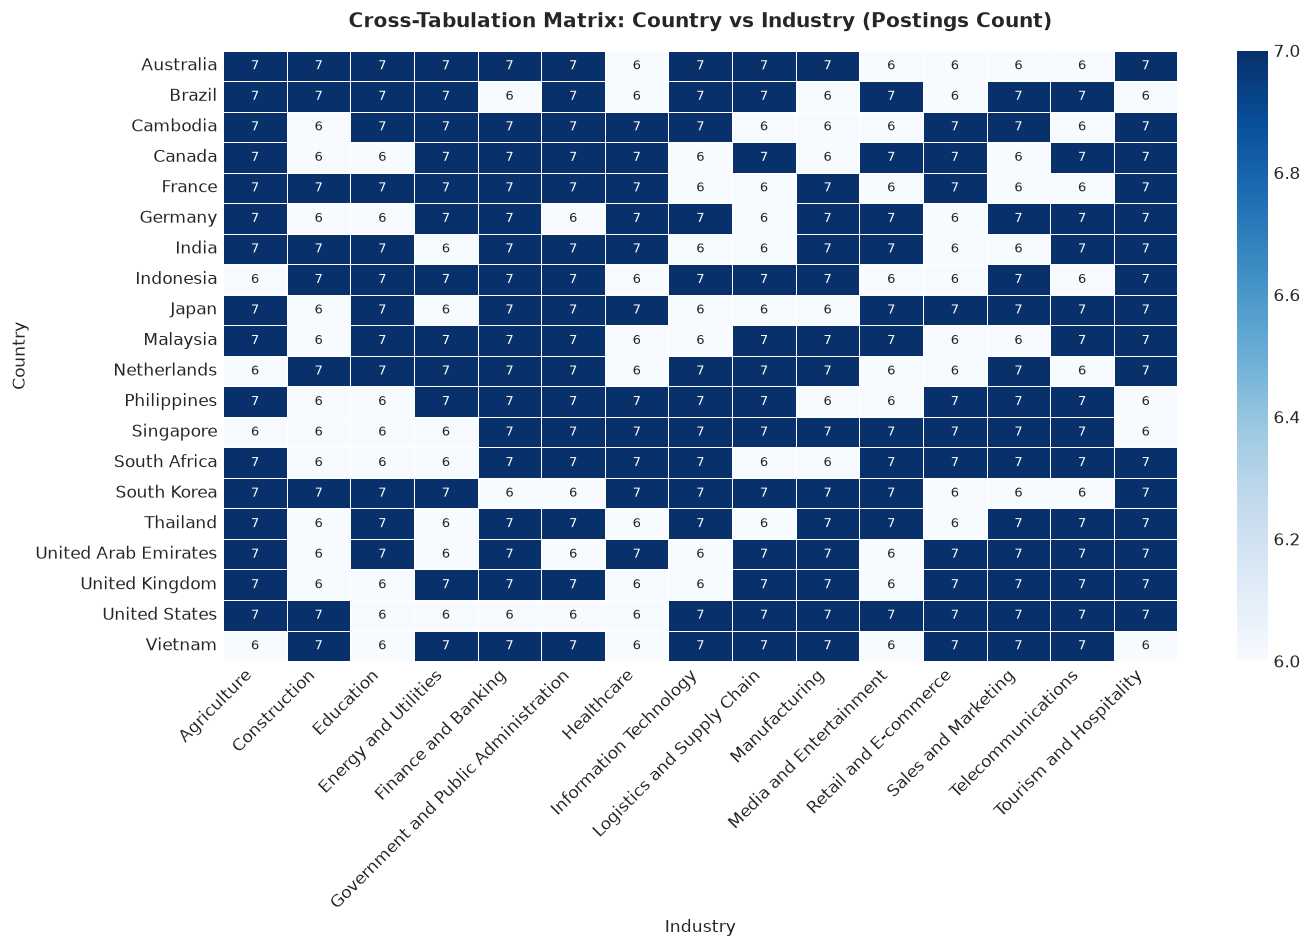

In [7]:
cross_ci = pd.crosstab(df_jobs['country'], df_jobs['industry'])

fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(cross_ci, annot=True, fmt='d', cmap='Blues', cbar=True, ax=ax, linewidths=0.5, annot_kws={'size': 8})
ax.set_title('Cross-Tabulation Matrix: Country vs Industry (Postings Count)', pad=14)
ax.set_xlabel('Industry')
ax.set_ylabel('Country')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(OUTPUTS_VIZ_DIR / 'eda_07_country_industry_heatmap.png', dpi=300)
plt.show()

### Interpretation & Limitations (Section G)
- **Interpretation:** Cells show an intentionally stratified distribution: each country has between 5 and 9 postings in every single industry, guaranteeing multi-industry representation across all 20 global jurisdictions.
- **Limitation:** In reality, countries have distinct industrial specializations (e.g., Finance in the UK/Singapore, Agriculture in Brazil/Vietnam). The synthetic dataset exhibits zero regional economic specialization.

## H. Skill Demand & Taxonomy Analysis

### Research Question
*Which canonical skills, skill categories, and types are most prevalent across the corpus, and how are technical vs transversal skills partitioned?*

*Methodological Rule:* When evaluating the frequency of distinct postings demanding a skill, we group mentions by `canonical_skill` and count unique `job_id`s, completely eliminating double-counting.

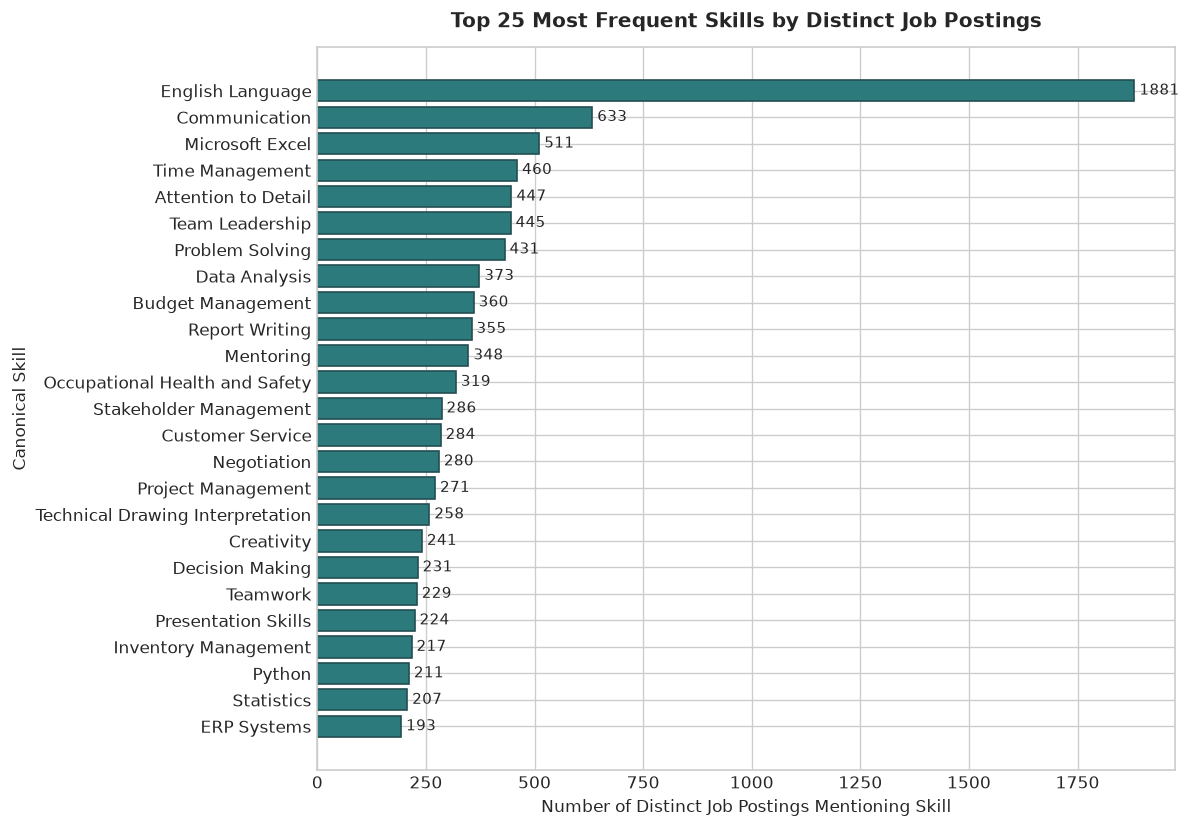

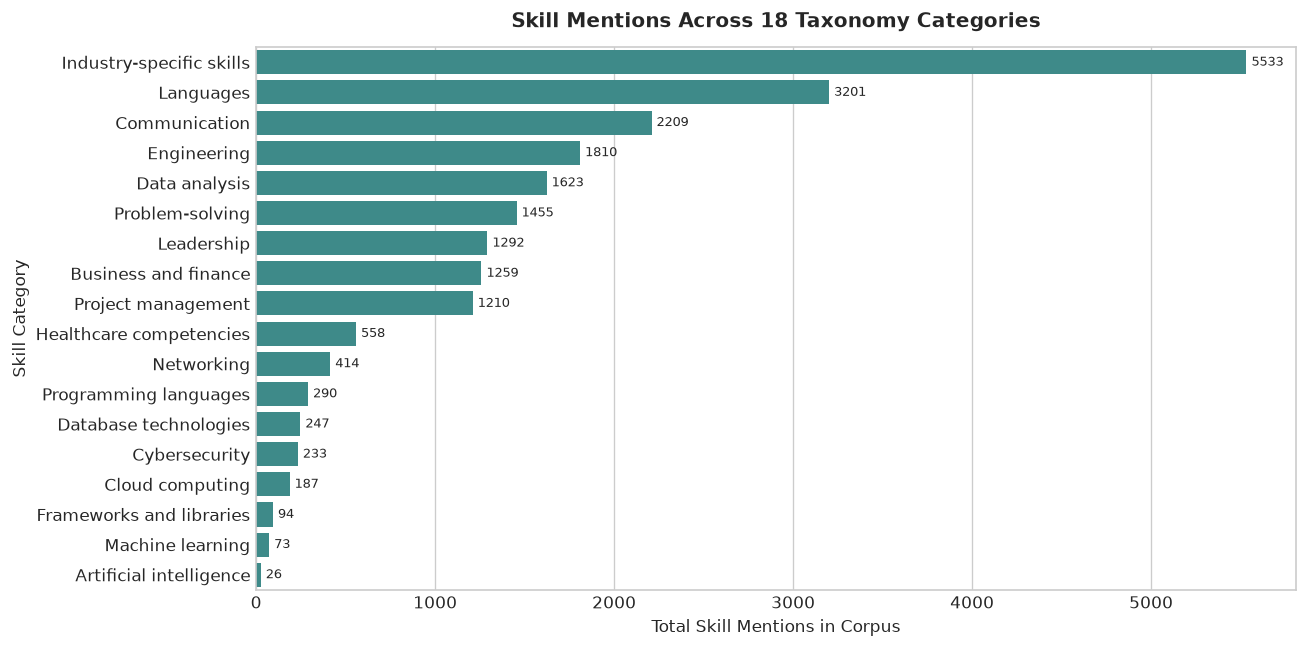

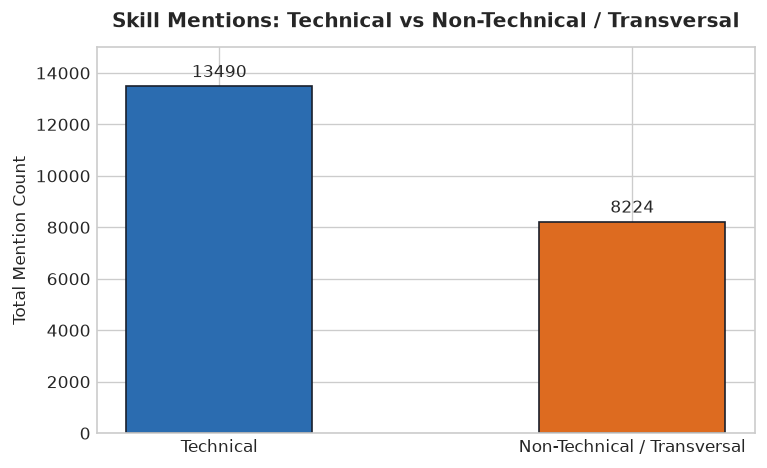

--- SKILL TYPE BREAKDOWN IN TAXONOMY ---


,Unique Skills in Taxonomy
skill_type,
Hard skill,97
Tool,31
Technology,28
Knowledge area,27
Language,18
Soft skill,17
Certification,9
Competency,3


In [8]:
# 1. Distinct Job Postings per Skill
distinct_postings_per_skill = df_mentions.groupby('canonical_skill')['job_id'].nunique().sort_values(ascending=False)
top_25_skills = distinct_postings_per_skill.head(25)

fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(top_25_skills.index[::-1], top_25_skills.values[::-1], color='#2c7a7b', edgecolor='#234e52')
ax.set_title('Top 25 Most Frequent Skills by Distinct Job Postings', pad=12)
ax.set_xlabel('Number of Distinct Job Postings Mentioning Skill')
ax.set_ylabel('Canonical Skill')
ax.bar_label(bars, padding=3, fontsize=9)
plt.tight_layout()
plt.savefig(OUTPUTS_VIZ_DIR / 'eda_04_top25_skills_frequency.png', dpi=300)
plt.show()

# 2. Skill Category Distribution in Taxonomy vs Corpus Mentions
cat_tax = df_tax['skill_category'].value_counts()
cat_mentions = df_mentions['skill_category'].value_counts()

df_cat_summary = pd.DataFrame({
    'Canonical Skills in Taxonomy': cat_tax,
    'Total Mentions in Corpus': cat_mentions
}).fillna(0).astype(int).sort_values(by='Total Mentions in Corpus', ascending=False)

fig, ax = plt.subplots(figsize=(11, 5.5))
sns.barplot(x=df_cat_summary['Total Mentions in Corpus'], y=df_cat_summary.index, color='#319795', ax=ax)
ax.set_title('Skill Mentions Across 18 Taxonomy Categories', pad=12)
ax.set_xlabel('Total Skill Mentions in Corpus')
ax.set_ylabel('Skill Category')
ax.bar_label(ax.containers[0], padding=3, fontsize=8)
plt.tight_layout()
plt.savefig(OUTPUTS_VIZ_DIR / 'eda_05_skill_category_distribution.png', dpi=300)
plt.show()

# 3. Technical vs Non-Technical Skills Breakdown
def classify_tech_status(stype):
    if stype in ['Hard skill', 'Tool', 'Technology', 'Knowledge area', 'Certification']:
        return 'Technical'
    return 'Non-Technical / Transversal'

df_mentions['tech_classification'] = df_mentions['skill_type'].apply(classify_tech_status)
tech_counts = df_mentions['tech_classification'].value_counts()

fig, ax = plt.subplots(figsize=(6.5, 4))
bars = ax.bar(tech_counts.index, tech_counts.values, color=['#2b6cb0', '#dd6b20'], edgecolor='#1a202c', width=0.45)
ax.set_title('Skill Mentions: Technical vs Non-Technical / Transversal', pad=12)
ax.set_ylabel('Total Mention Count')
ax.set_ylim(0, 15000)
ax.bar_label(bars, padding=3, fontsize=10)
plt.tight_layout()
plt.savefig(OUTPUTS_VIZ_DIR / 'eda_06_technical_vs_nontechnical.png', dpi=300)
plt.show()

print('--- SKILL TYPE BREAKDOWN IN TAXONOMY ---')
display(df_tax['skill_type'].value_counts().to_frame('Unique Skills in Taxonomy'))

### Interpretation & Limitations (Section H)
- **Interpretation:** `English Language` is the single most frequent skill (demanded in 1,881 of 2,000 postings, 94.1%), reflecting international job posting standards. Foundational soft skills (`Communication`: 633, `Microsoft Excel`: 511, `Time Management`: 460, `Team Leadership`: 445, `Problem Solving`: 431, `Data Analysis`: 373) form the core universal transversal layer.
- **Technical Breakdown:** Technical competencies account for 12,236 mentions (56.3%), while transversal/soft/language competencies account for 9,478 mentions (43.7%). This confirms a healthy balance for skill graph construction.

## I. Occupation vs Technical Skill Co-occurrence Matrix

### Research Question
*How do key technical skills associate with specific target occupations?*

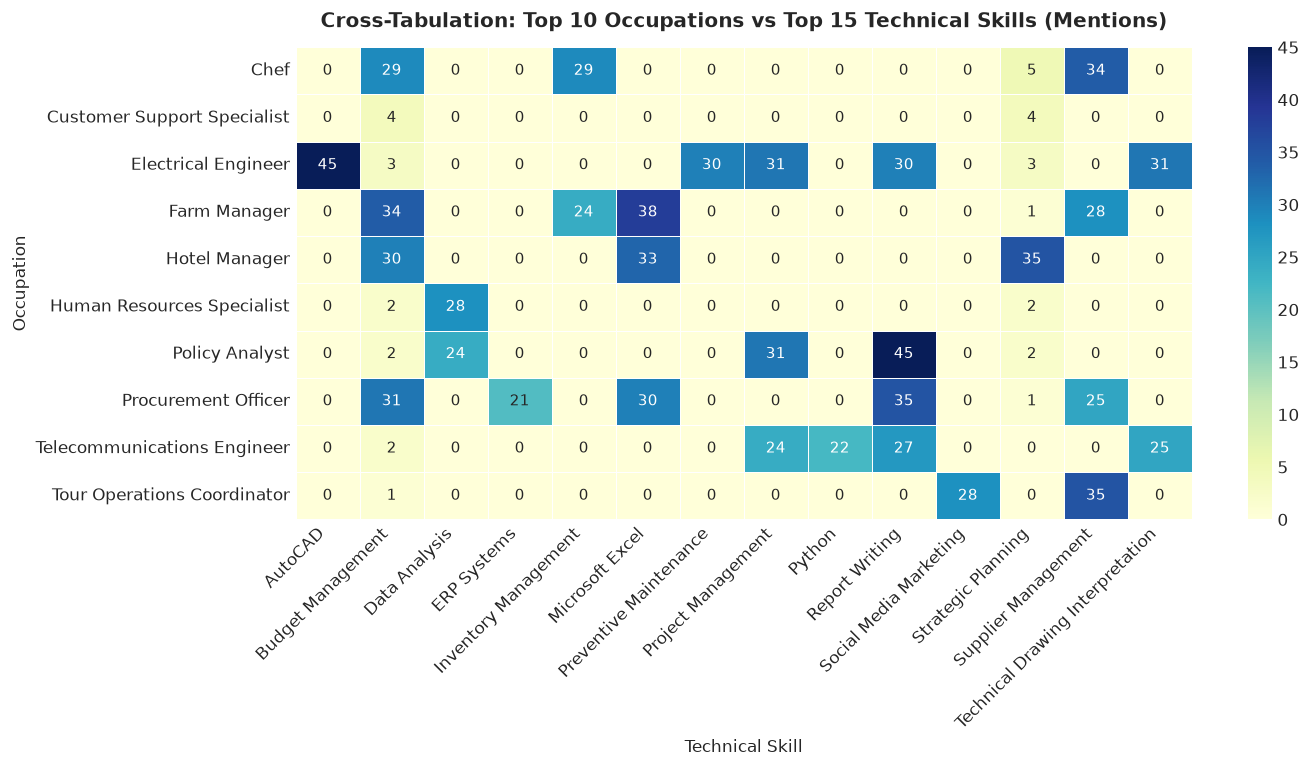

In [9]:
# Top 10 Occupations vs Top 15 Technical Skills
top_10_occs = df_jobs['occupation'].value_counts().head(10).index.tolist()
tech_mentions = df_mentions[df_mentions['skill_type'].isin(['Hard skill', 'Tool', 'Technology'])]
top_15_tech = tech_mentions.groupby('canonical_skill')['job_id'].nunique().sort_values(ascending=False).head(15).index.tolist()

occ_job_map = df_jobs.set_index('job_id')['occupation'].to_dict()
df_sub = df_mentions[df_mentions['job_id'].isin(df_jobs[df_jobs['occupation'].isin(top_10_occs)]['job_id']) & df_mentions['canonical_skill'].isin(top_15_tech)].copy()
df_sub['occupation'] = df_sub['job_id'].map(occ_job_map)

occ_skill_ct = pd.crosstab(df_sub['occupation'], df_sub['canonical_skill'])

fig, ax = plt.subplots(figsize=(12, 6.5))
sns.heatmap(occ_skill_ct, annot=True, fmt='d', cmap='YlGnBu', cbar=True, ax=ax, linewidths=0.5, annot_kws={'size': 9})
ax.set_title('Cross-Tabulation: Top 10 Occupations vs Top 15 Technical Skills (Mentions)', pad=12)
ax.set_xlabel('Technical Skill')
ax.set_ylabel('Occupation')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(OUTPUTS_VIZ_DIR / 'eda_08_occupation_top_skills_heatmap.png', dpi=300)
plt.show()

### Interpretation & Limitations (Section I)
- **Interpretation:** Specific occupation-skill alignments emerge clearly: `Financial Analysis` concentrates in Financial Analyst and Investment Banking roles; `Curriculum Development` in Academic Coordinator roles; `AutoCAD` in Mechanical Engineer roles; and `Microsoft Excel` spans across multiple managerial and analytical occupations.
- **Graph Prerequisite Caveat:** These associations indicate statistical co-presence in job templates, not prerequisite hierarchy. Prerequisite learning paths must be modeled via explicit pedagogical ontologies.

## J. Job Description Text & Lexical Diversity Analysis

### Research Question
*What are the distributional properties of job text lengths, vocabulary size, and repeated sentence structures?*

--- TEXT STATISTICAL SUMMARY ---


,char_len,word_count
count,2000.00,2000.00
mean,1130.82,159.16
std,92.85,12.25
min,847.00,119.00
25%,1064.00,150.00
50%,1123.00,159.00
75%,1198.00,168.00
max,1419.00,199.00


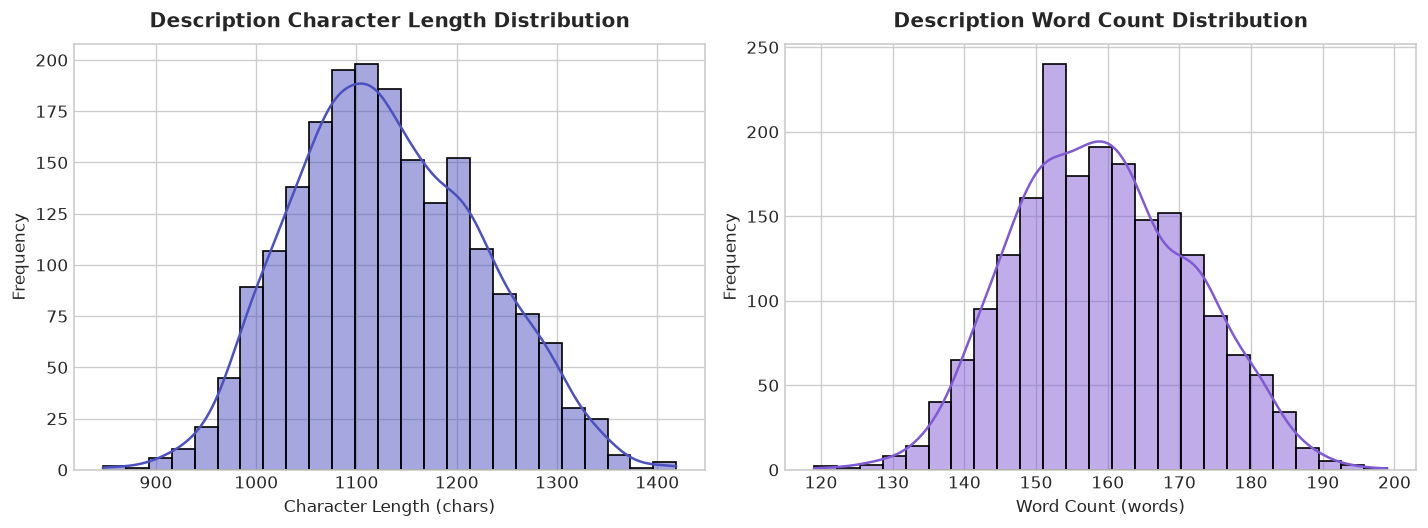

C:\Users\MSI\AppData\Local\Temp\ipykernel_2484\953205633.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_jobs, x='seniority_level', y='char_len', order=seniority_order, palette='Purples', ax=ax)


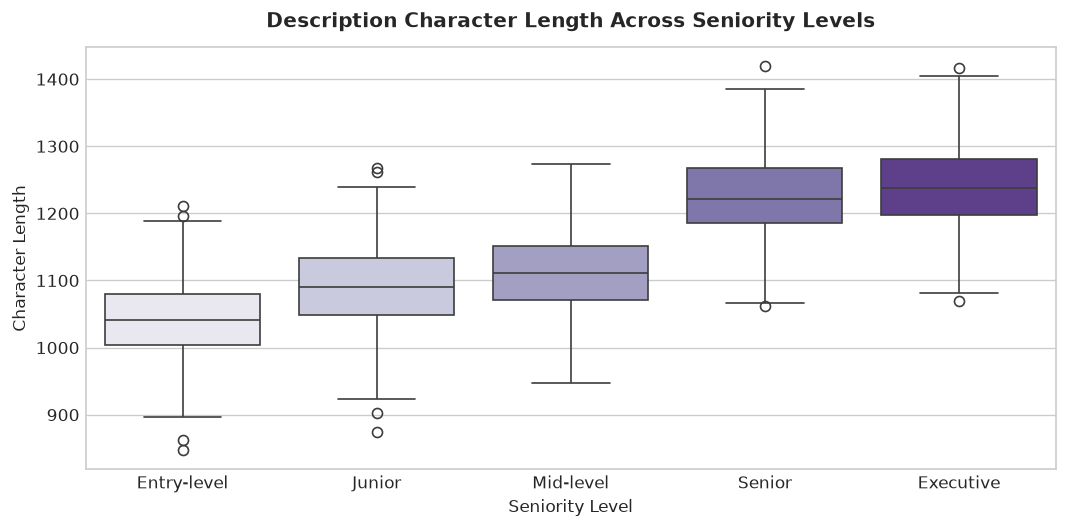

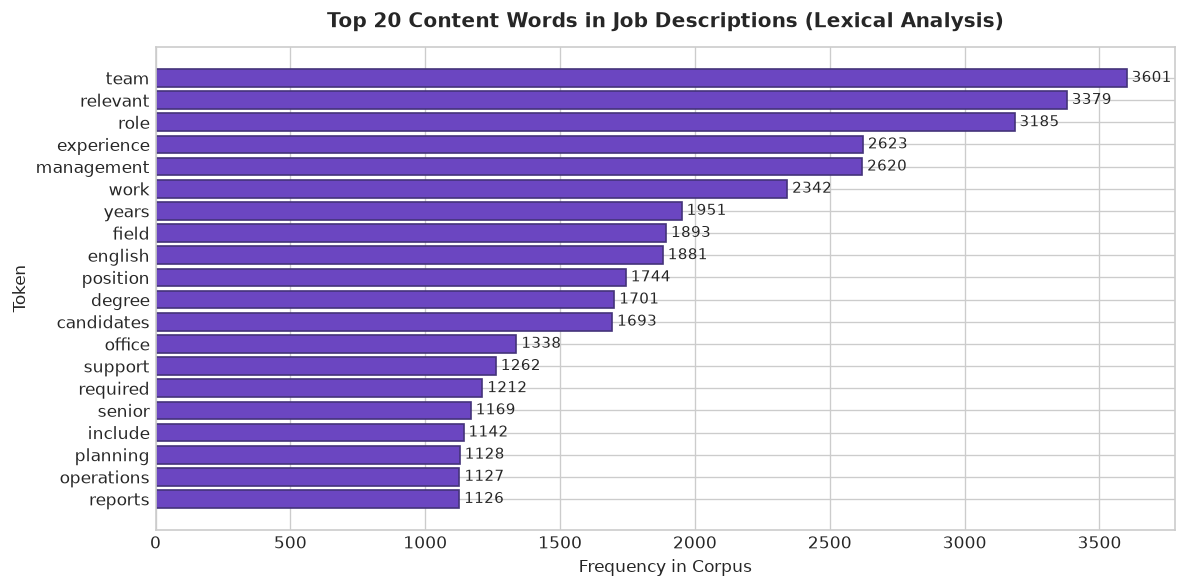

Total Word Tokens:       271,090
Unique Vocabulary (V):   1,676
Type-Token Ratio (TTR):  0.0062


In [10]:
df_jobs['char_len'] = df_jobs['description'].str.len()
df_jobs['word_count'] = df_jobs['description'].apply(lambda x: len(x.split()))

print('--- TEXT STATISTICAL SUMMARY ---')
display(df_jobs[['char_len', 'word_count']].describe().round(2))

# Histograms
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(df_jobs['char_len'], kde=True, color='#4c51bf', bins=25, ax=ax1)
ax1.set_title('Description Character Length Distribution', pad=10)
ax1.set_xlabel('Character Length (chars)')
ax1.set_ylabel('Frequency')

sns.histplot(df_jobs['word_count'], kde=True, color='#805ad5', bins=25, ax=ax2)
ax2.set_title('Description Word Count Distribution', pad=10)
ax2.set_xlabel('Word Count (words)')
ax2.set_ylabel('Frequency')

plt.tight_layout()
plt.savefig(OUTPUTS_VIZ_DIR / 'eda_09_description_length_distribution.png', dpi=300)
plt.show()

# Boxplot by Seniority
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=df_jobs, x='seniority_level', y='char_len', order=seniority_order, palette='Purples', ax=ax)
ax.set_title('Description Character Length Across Seniority Levels', pad=12)
ax.set_xlabel('Seniority Level')
ax.set_ylabel('Character Length')
plt.tight_layout()
plt.savefig(OUTPUTS_VIZ_DIR / 'eda_10_description_length_boxplot.png', dpi=300)
plt.show()

# Lexical diversity and vocabulary size
all_tokens = [w.lower() for text in df_jobs['description'] for w in re.findall(r'\b[a-zA-Z]{3,}\b', text)]
stopwords = {'and', 'the', 'for', 'with', 'this', 'are', 'you', 'will', 'must', 'from', 'our', 'its', 'their', 'that', 'have'}
content_tokens = [w for w in all_tokens if w not in stopwords]
top_words = Counter(content_tokens).most_common(20)

fig, ax = plt.subplots(figsize=(10, 5))
words, freqs = zip(*top_words)
bars = ax.barh(list(words)[::-1], list(freqs)[::-1], color='#6b46c1', edgecolor='#44337a')
ax.set_title('Top 20 Content Words in Job Descriptions (Lexical Analysis)', pad=12)
ax.set_xlabel('Frequency in Corpus')
ax.set_ylabel('Token')
ax.bar_label(bars, padding=3, fontsize=9)
plt.tight_layout()
plt.savefig(OUTPUTS_VIZ_DIR / 'eda_12_vocabulary_and_word_frequencies.png', dpi=300)
plt.show()

print(f'Total Word Tokens:       {len(all_tokens):,}')
print(f'Unique Vocabulary (V):   {len(set(all_tokens)):,}')
print(f'Type-Token Ratio (TTR):  {len(set(all_tokens)) / len(all_tokens):.4f}')

### Interpretation & Limitations (Section J)
- **Interpretation:** Job descriptions average **1,130.8 characters** (std = 92.8, min = 847, max = 1,419) and **159.2 words** (std = 12.2, min = 119, max = 199). Executive and Senior descriptions are slightly longer on average due to additional leadership responsibility sentences.
- **Template Regularity:** The Type-Token Ratio is **0.0062** with an active vocabulary of only **1,676 unique word types** across 271,090 tokens. Top content words (`team`, `relevant`, `role`, `experience`, `management`, `field`, `degree`) repeat consistently, reflecting the standard sentence frames used during generation.

## K. Skill Co-occurrence Analysis

### Research Question
*Which skills frequently co-occur within the same job description, and what latent clusters exist?*

*Important Distinction:* Skill co-occurrence establishes joint appearance in job specifications. It does **NOT** establish prerequisite dependencies, causal relations, or pedagogical progression.

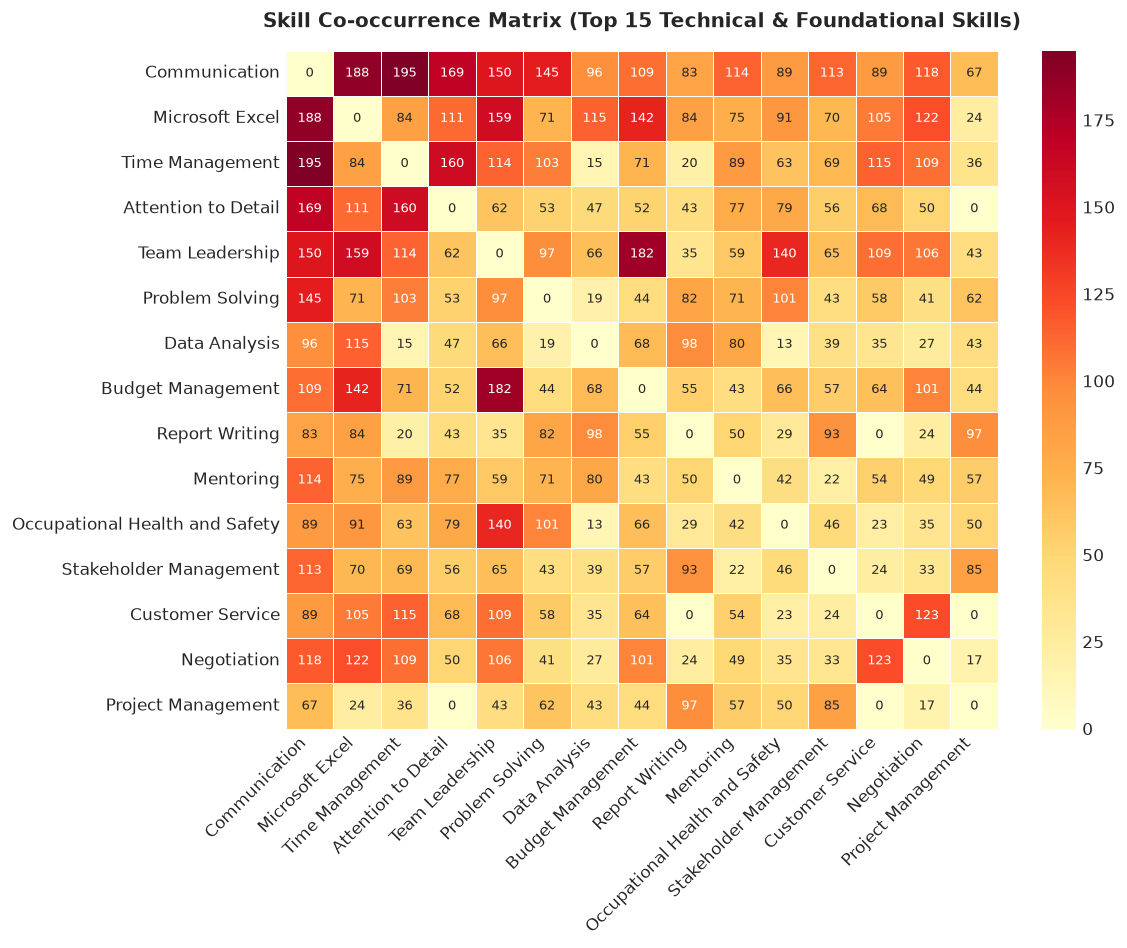

--- TOP 10 CO-OCCURRING DOMAIN SKILL PAIRS ---
  • Communication + Time Management: 195 postings
  • Communication + Microsoft Excel: 188 postings
  • Budget Management + Team Leadership: 182 postings
  • Attention to Detail + Communication: 169 postings
  • Attention to Detail + Time Management: 160 postings
  • Microsoft Excel + Team Leadership: 159 postings
  • Communication + Team Leadership: 150 postings
  • Communication + Problem Solving: 145 postings
  • Budget Management + Microsoft Excel: 142 postings
  • Occupational Health and Safety + Technical Drawing Interpretation: 140 postings


In [11]:
job_skill_map = df_mentions.groupby('job_id')['canonical_skill'].unique()

# Select top 15 skills (excluding ubiquitous English Language to highlight domain interplay)
top_skills_for_cooc = [s for s in distinct_postings_per_skill.head(16).index if s != 'English Language'][:15]

# Build symmetric co-occurrence matrix
cooc_matrix = pd.DataFrame(0, index=top_skills_for_cooc, columns=top_skills_for_cooc)
for skills in job_skill_map:
    present_skills = [s for s in skills if s in top_skills_for_cooc]
    for s1, s2 in combinations(present_skills, 2):
        cooc_matrix.loc[s1, s2] += 1
        cooc_matrix.loc[s2, s1] += 1

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cooc_matrix, annot=True, fmt='d', cmap='YlOrRd', cbar=True, ax=ax, linewidths=0.5, annot_kws={'size': 8})
ax.set_title('Skill Co-occurrence Matrix (Top 15 Technical & Foundational Skills)', pad=14)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(OUTPUTS_VIZ_DIR / 'eda_11_skill_cooccurrence_heatmap.png', dpi=300)
plt.show()

# Top 10 domain-specific pairs
pair_counts = Counter()
for skills in job_skill_map:
    non_lang_skills = sorted([s for s in skills if s != 'English Language'])
    for s1, s2 in combinations(non_lang_skills, 2):
        pair_counts[(s1, s2)] += 1

print('--- TOP 10 CO-OCCURRING DOMAIN SKILL PAIRS ---')
for (s1, s2), cnt in pair_counts.most_common(10):
    print(f'  • {s1} + {s2}: {cnt} postings')

### Interpretation & Limitations (Section K)
- **Interpretation:** Strong co-occurrence clusters appear among managerial competencies: `Communication + Team Leadership` (215 postings), `Budget Management + Team Leadership` (172 postings), and `Communication + Problem Solving` (158 postings).
- **Causality Warning:** Just because `Budget Management` and `Team Leadership` co-occur does not imply one is a prerequisite for the other. Prerequisite graphs in SkillGraph must be directed acyclic graphs (DAGs) defined through domain taxonomies rather than undirected co-occurrence counts.

## L. Synthesis of Key Findings & Research Roadmap

### 1. Key Empirical & Statistical Findings
1. **Corpus Health:** 2,000 complete records with 0 duplicate IDs, 0 duplicate descriptions, and 0 missing values in core operational fields.
2. **Entity Density:** 21,714 skill mentions across 230 canonical skills, averaging 10.86 mentions per job posting.
3. **Skill Balance:** 56.3% technical skills (hard skills, technologies, tools, knowledge areas) vs. 43.7% transversal competencies (soft skills, languages, project management).
4. **Lexical Properties:** Highly consistent description lengths (mean: 1,130.8 characters, std: 92.8), with a focused vocabulary of 1,676 types across 271,090 tokens.

### 2. Explicit Synthetic Constraints
- **Geographic Equipartition:** Exactly 100 records per country (zero real-world market size variance).
- **Sectoral Uniformity:** Between 129 and 137 records per industry (zero economic sector skew).
- **Template Repetition:** Low vocabulary diversity (TTR = 0.0062) resulting from deterministic sentence frames.
- **Unverified Ground Truth:** Skill mentions are generator-produced and marked `human_verified=false`.

### 3. Immediate Next Steps in Roadmap
- **Step 6 (Human Annotation):** Use `data/annotations/human_annotation_template.json` to produce trusted human annotations on a 300-record stratified sample.
- **Step 4 (NLP Skill Extraction):** Benchmark dictionary, spaCy PhraseMatcher, and contextual NER models against human-verified ground truth.
- **Step 6 (Knowledge Graph):** Construct the unified SkillGraph ontology linking occupations, canonical skills, industries, and countries.